# 02 - Monotonic WoE Binning & IV Feature Selection
`WoE = ln(%good / %bad)`, `IV = sum((%good - %bad) * WoE)`. Rules: keep **0.02 <= IV <= 0.50**; IV > 0.50 is *flagged for leakage review* rather than silently dropped; ECOA-protected attributes (SEX, MARRIAGE) are reported but never scored.

In [1]:
import os, sys; os.chdir('..') if os.path.basename(os.getcwd())=='notebooks' else None; sys.path.insert(0,'.')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, joblib, matplotlib.pyplot as plt
%matplotlib inline
from src.binning import WoEBinner
from src.features import NUM, CAT, PROTECTED
train, test = joblib.load('data/processed/split.joblib')
binners = {v: WoEBinner('num' if v in NUM else 'cat').fit(train[v].values, train.default.values) for v in NUM + CAT}
iv = pd.DataFrame({'variable': list(binners), 'IV': [b.iv_ for b in binners.values()], 'bins': [len(b.woe_) for b in binners.values()]}).sort_values('IV', ascending=False)
def decide(r):
    if r.variable in PROTECTED: return 'excluded (ECOA-protected)'
    if r.IV < 0.02: return 'drop: weak'
    return 'review: IV>0.5' if r.IV > 0.5 else 'keep'
iv['decision'] = iv.apply(decide, axis=1); display(iv.round(4).reset_index(drop=True))

,variable,IV,bins,decision
0,PAY_1,0.8790,4,review: IV>0.5
1,n_delq,0.8692,4,review: IV>0.5
2,max_delq,0.7793,3,review: IV>0.5
3,PAY_2,0.5556,2,review: IV>0.5
4,PAY_3,0.4182,3,keep
5,PAY_4,0.3659,3,keep
6,PAY_5,0.3413,3,keep
7,PAY_6,0.2939,3,keep
8,LIMIT_BAL,0.1981,8,keep
9,PAY_AMT1,0.1759,7,keep


## Monotonicity check & example WoE profiles

numeric variables with monotone WoE: 25 / 25


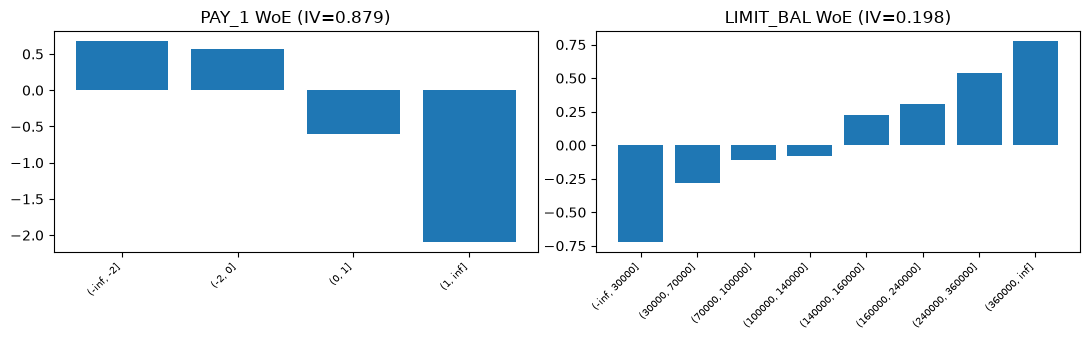

,bin,count,pct,bad_rate,woe
0,"(-inf, -2]",1933,0.092,0.126,0.674
1,"(-2, 0]",14256,0.679,0.138,0.569
2,"(0, 1]",2616,0.125,0.342,-0.605
3,"(1, inf]",2195,0.105,0.698,-2.096


In [2]:
mono = {v: bool(np.all(np.diff(b.woe_)>=0) or np.all(np.diff(b.woe_)<=0)) for v,b in binners.items() if v in NUM}
print('numeric variables with monotone WoE: %d / %d' % (sum(mono.values()), len(mono)))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, v in zip(ax, ['PAY_1', 'LIMIT_BAL']):
    t = binners[v].table_; a.bar(range(len(t)), t.woe); a.set_xticks(range(len(t))); a.set_xticklabels(t.bin, rotation=45, ha='right', fontsize=7); a.set_title(f'{v} WoE (IV={binners[v].iv_:.3f})')
plt.tight_layout(); plt.show(); display(binners['PAY_1'].table_.round(3))

In [3]:
joblib.dump(dict(binners=binners, iv=iv), 'data/processed/binning.joblib'); print('saved')

saved
